In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.python.client import device_lib
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import os

# === Step 0C: (optional) helper for dataset sizes ===
def ds_size(ds):
    c = tf.data.experimental.cardinality(ds)
    return int(c.numpy()) if c >= 0 else None

# === Step 0A: Make GPU allocation behave (place this RIGHT AFTER importing TF) ===
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

# === Step 0B: tf.data options to avoid thread/memory explosions ===
AUTOTUNE = tf.data.AUTOTUNE
opts = tf.data.Options()
opts.threading.private_threadpool_size = 4
opts.threading.max_intra_op_parallelism = 1

2025-08-16 21:26:11.662815: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1755372371.780133   10840 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1755372371.810104   10840 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1755372372.025970   10840 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1755372372.025999   10840 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1755372372.026001   10840 computation_placer.cc:177] computation placer alr

In [2]:
# === Step 1: Load dataset (RAW) ===
train_raw = image_dataset_from_directory(
    "../dataset/",
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(256, 256),
    batch_size=4
)

val_raw = image_dataset_from_directory(
    "../dataset/",
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(256, 256),
    batch_size=4
)

# Now safe to call
train_batches = ds_size(train_raw)
val_batches   = ds_size(val_raw)
steps_per_epoch = train_batches


# (Safe to print devices now)
print(device_lib.list_local_devices())

class_names = train_raw.class_names
print("Class names:", class_names)
swee_index = class_names.index("Swee Waxbill")

Found 31927 files belonging to 6 classes.
Using 25542 files for training.


I0000 00:00:1755372379.535406   10840 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2554 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650, pci bus id: 0000:01:00.0, compute capability: 7.5


Found 31927 files belonging to 6 classes.
Using 6385 files for validation.
[name: "/device:CPU:0"
device_type: "CPU"
memory_limit: 268435456
locality {
}
incarnation: 14576600855020636018
xla_global_id: -1
, name: "/device:GPU:0"
device_type: "GPU"
memory_limit: 2678390784
locality {
  bus_id: 1
  links {
  }
}
incarnation: 15974955336335736059
physical_device_desc: "device: 0, name: NVIDIA GeForce GTX 1650, pci bus id: 0000:01:00.0, compute capability: 7.5"
xla_global_id: 416903419
]
Class names: ['Cape Sparrow', 'Cape White-eye', 'Masked Weaver', 'Southern Double-collared Sunbird', 'Squirrel', 'Swee Waxbill']


I0000 00:00:1755372382.737895   10840 gpu_device.cc:2019] Created device /device:GPU:0 with 2554 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650, pci bus id: 0000:01:00.0, compute capability: 7.5


In [3]:
# === Step 2: Define augmentation and normalization ===
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.2),
])

normalization_layer = tf.keras.layers.Rescaling(1./255)

In [4]:
# === Step 3: Custom preprocessing to apply more augmentation for Swee Waxbill ===
def custom_preprocess(x, y):
    x = normalization_layer(x)
    # Apply heavier augmentation to Swee Waxbill class
    is_swee = tf.equal(y, swee_index)
    x_augmented = data_augmentation(x, training=True)
    x_augmented = tf.where(is_swee[:, tf.newaxis, tf.newaxis, tf.newaxis], 
                           data_augmentation(x_augmented, training=True), 
                           x_augmented)
    return x_augmented, y

In [5]:
# === Step 4: CACHING BEFORE MAP/SHUFFLE + conservative prefetch ===
# Put cache files on a fast local disk; remove old caches if you change the pipeline.
cache_dir = os.path.expanduser("~/tf-cache")
os.makedirs(cache_dir, exist_ok=True)

train_raw = train_raw.cache(os.path.join(cache_dir, "train.tf-data"))
val_raw   = val_raw.cache(os.path.join(cache_dir, "val.tf-data"))

# Now map AFTER cache so we don't cache augmented tensors
train_ds = train_raw.map(custom_preprocess, num_parallel_calls=AUTOTUNE)
val_ds   = val_raw.map(lambda x, y: (normalization_layer(x), y),
                       num_parallel_calls=AUTOTUNE)

# Shuffle with a decent buffer; keep prefetch small at first
shuffle_buf = 1000

train_ds = (train_ds
    .repeat()
            .shuffle(buffer_size=shuffle_buf, reshuffle_each_iteration=True)
            .prefetch(1)                    # start conservative; bump later if stable
            .with_options(opts))

val_ds = (val_ds
          .prefetch(1)
          .with_options(opts))

2025-08-16 21:26:23.367368: W tensorflow/core/kernels/data/cache_dataset_ops.cc:333] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


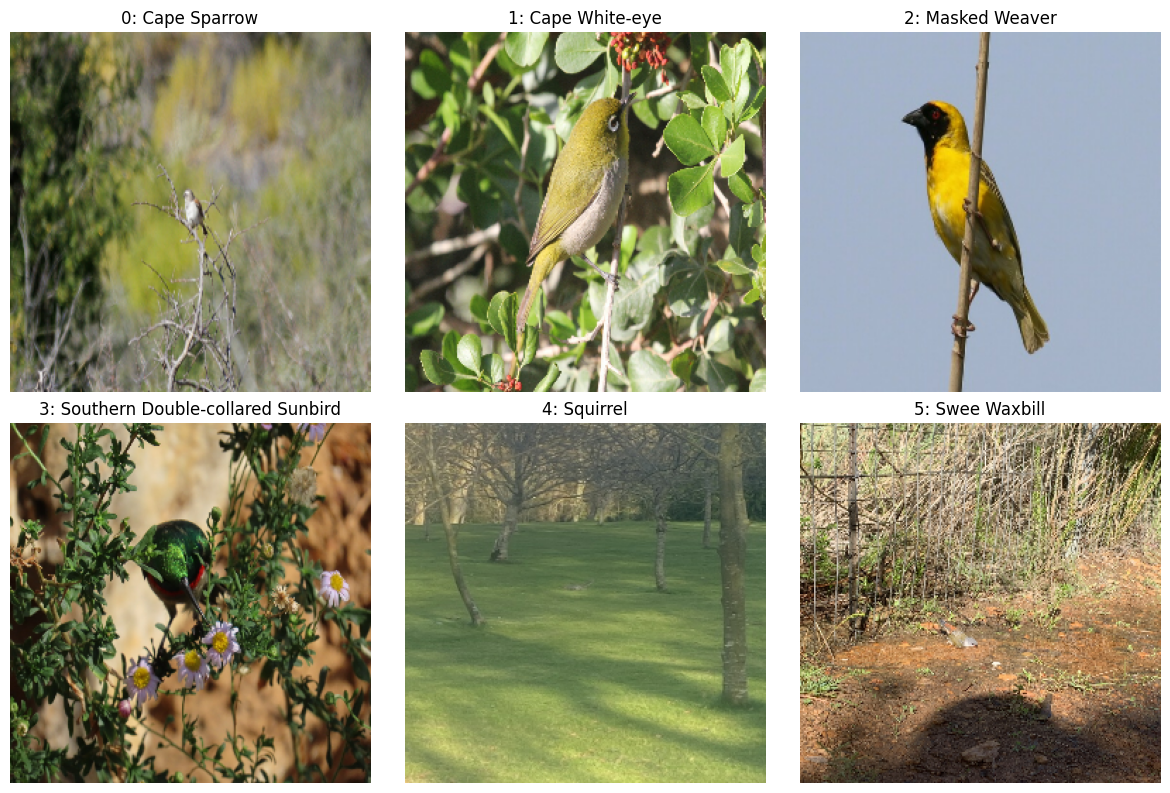

In [6]:
# Make sure class_names is already defined: class_names = train_raw.class_names
k = len(class_names)

# Collect one example per class
examples = [None] * k
for img_batch, y_batch in train_raw.unbatch():
    y = int(y_batch.numpy())
    if examples[y] is None:
        examples[y] = (img_batch.numpy(), y)
    if all(e is not None for e in examples):
        break

# Plot
cols = min(k, 3)
rows = (k + cols - 1) // cols
plt.figure(figsize=(4*cols, 4*rows))
for i, item in enumerate(examples):
    plt.subplot(rows, cols, i+1)
    plt.imshow(item[0].astype("uint8"))
    plt.title(f"{i}: {class_names[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [7]:
# === Step 5: Build the model ===
model = models.Sequential([
    layers.Input(shape=(256, 256, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(256, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.4),
    layers.Dense(6, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss=SparseCategoricalCrossentropy(from_logits=False), # experiment with better loss functions for this problem
    metrics=['accuracy']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,006 (1.62 MB)

 Trainable params: 423,046 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [8]:
# === Step 6: Calculate class weights ===
# Based on known image counts: 5500 for all, 4427 for Swee Waxbill
# ['Cape Sparrow', 'Cape White-eye', 'Masked Weaver', 'Southern Double-collared Sunbird', 'Squirrel', 'Swee Waxbill']
image_counts = [5500, 5500, 5500, 5500, 5500, 4427]  # Match class_names order
labels = []
for i, count in enumerate(image_counts):
    labels.extend([i] * count)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(labels),
    y=np.array(labels)
)

class_weight_dict = dict(enumerate(class_weights))
print("Class weights:", class_weight_dict)

Class weights: {0: 0.9674848484848485, 1: 0.9674848484848485, 2: 0.9674848484848485, 3: 0.9674848484848485, 4: 0.9674848484848485, 5: 1.2019802725698365}


In [9]:
# === Step 7: Fit the model ===
early_stop = EarlyStopping(monitor='val_accuracy', patience=15, restore_best_weights=True)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=65,
    steps_per_epoch=steps_per_epoch,
    callbacks=[early_stop],
    class_weight=class_weight_dict
)

Epoch 1/65


2025-08-16 21:26:38.151377: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:19: Filling up shuffle buffer (this may take a while): 264 of 1000
2025-08-16 21:26:58.053212: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:452] ShuffleDatasetV3:19: Filling up shuffle buffer (this may take a while): 793 of 1000
2025-08-16 21:27:06.157757: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:482] Shuffle buffer filled.
I0000 00:00:1755372426.165188   11223 service.cc:152] XLA service 0x6ffe34002bb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1755372426.165229   11223 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce GTX 1650, Compute Capability 7.5
2025-08-16 21:27:06.418734: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1755372427.032444   11223 cuda_dnn.cc:529] Loaded cuDN

   5/6386 ━━━━━━━━━━━━━━━━━━━━ 3:20 31ms/step - accuracy: 0.0000e+00 - loss: 2.7470

I0000 00:00:1755372433.327288   11223 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


5388/6386 ━━━━━━━━━━━━━━━━━━━━ 42s 42ms/step - accuracy: 0.2717 - loss: 1.9347

...

2025-08-16 21:31:40.476428: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:549] Omitted potentially buggy algorithm eng14{k25=0} for conv %cudnn-conv-bias-activation.12 = (f32[4,32,254,254]{3,2,1,0}, u8[0]{0}) custom-call(f32[4,3,256,256]{3,2,1,0} %bitcast.769, f32[32,3,3,3]{3,2,1,0} %bitcast.776, f32[32]{0} %bitcast.778), window={size=3x3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", metadata={op_type="Conv2D" op_name="sequential_1_1/conv2d_1/convolution" source_file="/home/devon/anaconda3/envs/bird-id/lib/python3.11/site-packages/tensorflow/python/framework/ops.py" source_line=1200}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"conv_result_scale":1,"activation_mode":"kRelu","side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false}
2025-08-16 21:31:40.643192: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:549] Omitted pote

6386/6386 ━━━━━━━━━━━━━━━━━━━━ 342s 46ms/step - accuracy: 0.2803 - loss: 1.9074 - val_accuracy: 0.2977 - val_loss: 2.4470
Epoch 2/65
   3/6386 ━━━━━━━━━━━━━━━━━━━━ 3:10 30ms/step - accuracy: 0.3056 - loss: 1.7482

2025-08-16 21:32:07.310557: W tensorflow/core/kernels/data/cache_dataset_ops.cc:333] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


6386/6386 ━━━━━━━━━━━━━━━━━━━━ 230s 36ms/step - accuracy: 0.4532 - loss: 1.4546 - val_accuracy: 0.3605 - val_loss: 2.9018
Epoch 3/65
6386/6386 ━━━━━━━━━━━━━━━━━━━━ 231s 36ms/step - accuracy: 0.5609 - loss: 1.2391 - val_accuracy: 0.4075 - val_loss: 5.8364
Epoch 4/65
6386/6386 ━━━━━━━━━━━━━━━━━━━━ 230s 36ms/step - accuracy: 0.5971 - loss: 1.1541 - val_accuracy: 0.4735 - val_loss: 3.7846
Epoch 5/65
6386/6386 ━━━━━━━━━━━━━━━━━━━━ 228s 36ms/step - accuracy: 0.6173 - loss: 1.1053 - val_accuracy: 0.2752 - val_loss: 16.6574
Epoch 6/65
6386/6386 ━━━━━━━━━━━━━━━━━━━━ 226s 35ms/step - accuracy: 0.6413 - loss: 1.0379 - val_accuracy: 0.3543 - val_loss: 4.9657
Epoch 7/65
6386/6386 ━━━━━━━━━━━━━━━━━━━━ 217s 34ms/step - accuracy: 0.6571 - loss: 1.0005 - val_accuracy: 0.4282 - val_loss: 7.1526
Epoch 8/65
6386/6386 ━━━━━━━━━━━━━━━━━━━━ 218s 34ms/step - accuracy: 0.6678 - loss: 0.9743 - val_accuracy: 0.3785 - val_loss: 10.7265
Epoch 9/65
6386/6386 ━━━━━━━━━━━━━━━━━━━━ 217s 34ms/step - accuracy: 0.6631 - 

2025-08-16 22:38:47.807153: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node sequential_3/random_zoom_1/ReadVariableOp/_40}}]] [type.googleapis.com/tensorflow.DerivedStatus='']
2025-08-16 22:38:47.807527: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node sequential_3/random_zoom_1/ReadVariableOp/_40}}]]
	 [[sequential_3/random_zoom_1/Add/_48]] [type.googleapis.com/tensorflow.DerivedStatus='']
2025-08-16 22:38:47.807726: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 16882173728183382711
2025-08-16 22:38:47.807739: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 3923294446707888671
2025-08-16 22:38:47.807750: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key

In [10]:
# === Step 8: Save model ===
model.save("6_Species_cnn_2025_08_15.keras")

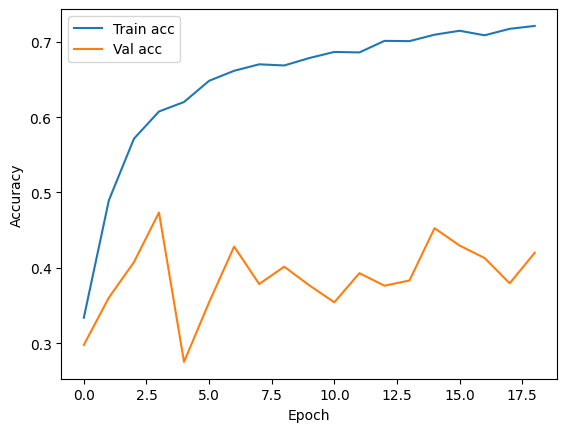

In [11]:
# === Step 9: Plot accuracy ===
plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


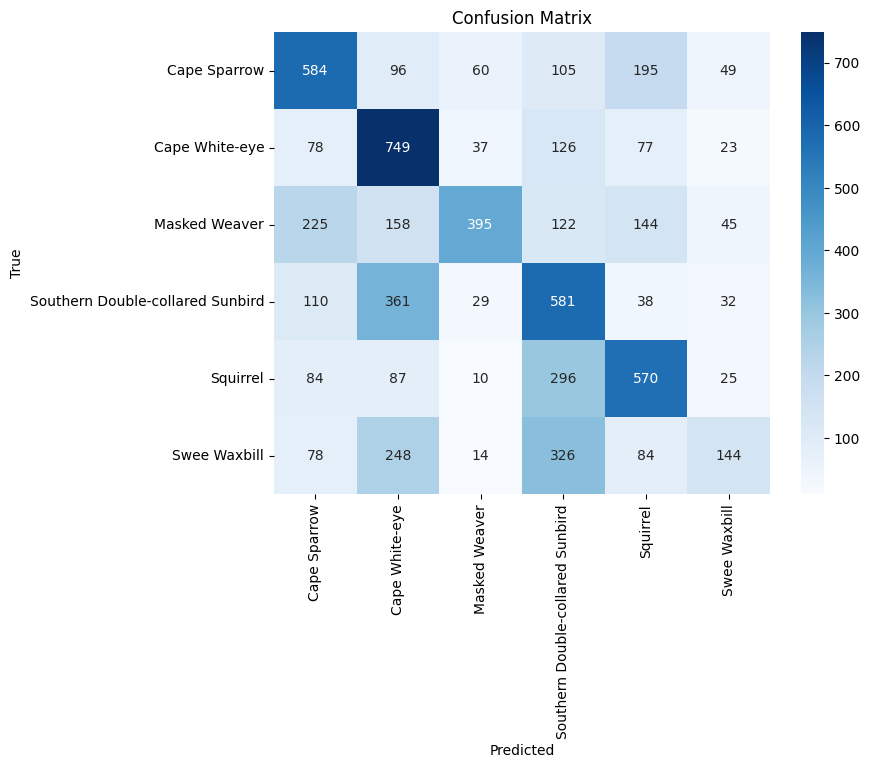

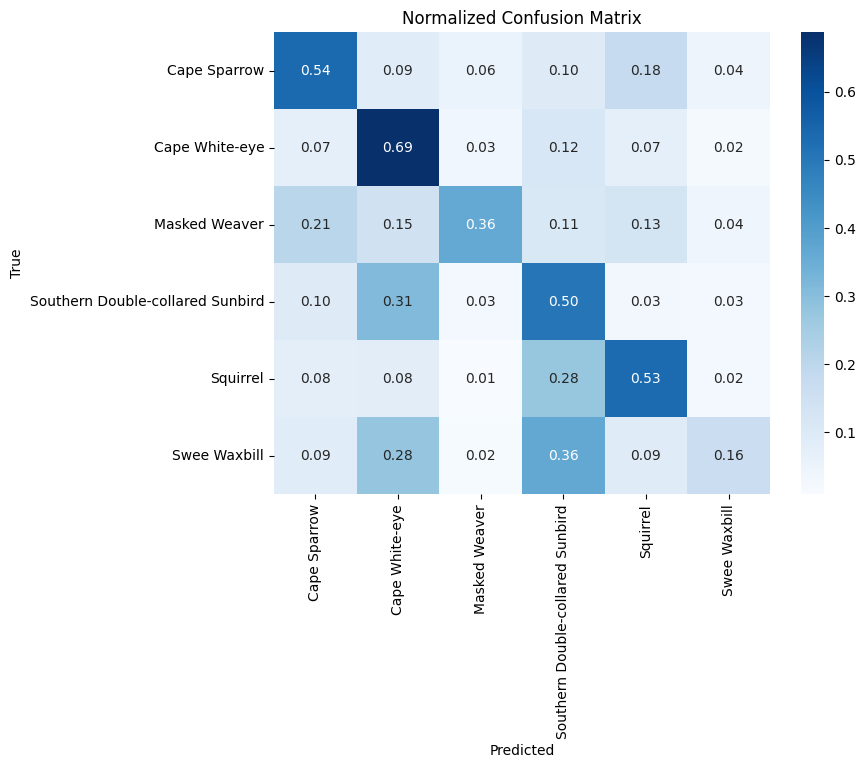

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# === Step 1: Collect predictions and true labels ===
y_true = []
y_pred = []

for images, labels in val_ds.unbatch():
    images = tf.expand_dims(images, axis=0)  # shape: (1, 256, 256, 3)
    preds = model.predict(images, verbose=0)
    y_true.append(int(labels))
    y_pred.append(np.argmax(preds))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# === Step 2: Compute confusion matrix ===
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]  # normalized

# === Step 3: Plot raw confusion matrix ===
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# === Step 4: Plot normalized confusion matrix ===
plt.figure(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Normalized Confusion Matrix')
plt.show()
